# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [9]:
ROLL_NO = 1024170063
NAME = "Gagandeep Kaur"

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [10]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [11]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [12]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170063   Name: Gagandeep Kaur   Fingerprint: D91DDBA3   Tickets: 15

Ticket_ID                                                                           Ticket_Text
      T01     Student portal stopped responding after restarting the system. Please resolve it.
      T02                           The server keeps disconnecting. I have tried several times!
      T03                I was locked out of the lms when I use mobile hotspot. This is urgent.
      T04 I couldn't connect to the e-mail before the assignment deadline. It worked yesterday.
      T05                      I can't open the WiFi during the lab. Is there another solution?
      T06                                                  Python 3.12 was installed yesterday.
      T07  Laptop failed to open when connected to campus Wi-Fi. The same problem occurs again.
      T08                                     The LMS has stopped syncing. It worked yesterday.
      T09                                         

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [15]:

# Q1. Preprocessing pipeline

rows = []
ticket_details = {}


for _, row in df.iterrows():
    ticket_id = row["Ticket_ID"]
    ticket = row["Ticket_Text"]

    result = process_ticket(ticket)

    sentences = result["sentences"]
    tokens = result["tokens"]
    punctuation_tokens = result["punct"]
    stopword_tokens = result["stops"]
    final_tokens = result["final"]

    rows.append({
        "Ticket": ticket_id,
        "Sentences": len(sentences),
        "Tokens": len(tokens),
        "Punctuation Tokens": len(punctuation_tokens),
        "Stopwords": len(stopword_tokens),
        "Unique Tokens": len(set(tokens)),
        "Final Tokens": len(final_tokens)
    })

    ticket_details[ticket_id] = {
        "Original Ticket": ticket,
        "Actual Tokens": tokens,
        "Punctuation Tokens": punctuation_tokens,
        "Stopwords": stopword_tokens,
        "Final Tokens": final_tokens
    }


result_df = pd.DataFrame(rows)


count_columns = [
    "Sentences", "Tokens", "Punctuation Tokens",
    "Stopwords", "Unique Tokens", "Final Tokens"
]

total_row = {"Ticket": "TOTAL"}

for col in count_columns:
    total_row[col] = result_df[col].sum()

result_df = pd.concat(
    [result_df, pd.DataFrame([total_row])],
    ignore_index=True
)

display(result_df)


first_ticket_id = df.iloc[0]["Ticket_ID"]
details = ticket_details[first_ticket_id]

print("\nDETAILED OUTPUT FOR", first_ticket_id)
print("Original Ticket:", details["Original Ticket"])
print("Actual Tokens:", details["Actual Tokens"])
print("Punctuation Tokens:", details["Punctuation Tokens"])
print("Stopwords:", details["Stopwords"])
print("Final Tokens:", details["Final Tokens"])


,Ticket,Sentences,Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,2,13,2,3,12,8
1,T02,2,11,2,3,11,6
2,T03,2,17,2,9,15,6
3,T04,2,16,2,6,14,8
4,T05,2,15,2,6,14,7
5,T06,1,6,1,1,6,4
6,T07,2,16,2,6,14,8
7,T08,2,10,2,3,9,5
8,T09,1,7,2,1,7,4
9,T10,2,13,2,6,12,5



DETAILED OUTPUT FOR T01
Original Ticket: Student portal stopped responding after restarting the system. Please resolve it.
Actual Tokens: ['student', 'portal', 'stopped', 'responding', 'after', 'restarting', 'the', 'system', '.', 'please', 'resolve', 'it', '.']
Punctuation Tokens: ['.', '.']
Stopwords: ['after', 'the', 'it']
Final Tokens: ['student', 'portal', 'stopped', 'responding', 'restarting', 'system', 'please', 'resolve']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*Some final tokens in my dataset, such as n't, 's, and ca, are not complete words. They come from contractions being split into separate tokens by word_tokenize(). For example, “can't” may be split into ca and n't, while “it's” may be split into it and 's. These fragments remain in the final tokens because the preprocessing pipeline removes punctuation tokens and stopwords but does not combine contraction fragments back into complete words.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [16]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code

import re

raw_tickets = df["Ticket_Text"].tolist()


all_texts = raw_tickets + TEST_LINES


for i, text in enumerate(all_texts, start=1):
    long_words = re.findall(r"\b[A-Za-z]{6,}\b", text)

    numbers = re.findall(r"\b\d+(?:\.\d+)*\b", text)

    capitalized_words = re.findall(r"\b[A-Z][a-zA-Z]*\b", text)

    vowel_words = re.findall(r"\b[aeiouAEIOU][a-zA-Z]*\b", text)

    print(f"\nText {i}: {text}")
    print("Words longer than 5 letters:", long_words)
    print("Numbers:", numbers)
    print("Capitalized words:", capitalized_words)
    print("Words starting with a vowel:", vowel_words)

# Replacement patterns
email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
url_pattern = r"https?://\S+|www\.[^\s]+"
phone_pattern = r"(?<!\w)(?:\+?\d{1,3}[- ]?)?(?:\d{3,5}[- ]?){1,3}\d{3,5}(?!\w)"

print("\n--- Replacement on TEST_LINES ---")

for line in TEST_LINES:
    result = re.sub(email_pattern, "<EMAIL>", line)
    result = re.sub(url_pattern, "<URL>", result)
    result = re.sub(phone_pattern, "<PHONE>", result)
    print(result)



Text 1: Student portal stopped responding after restarting the system. Please resolve it.
Words longer than 5 letters: ['Student', 'portal', 'stopped', 'responding', 'restarting', 'system', 'Please', 'resolve']
Numbers: []
Capitalized words: ['Student', 'Please']
Words starting with a vowel: ['after', 'it']

Text 2: The server keeps disconnecting. I have tried several times!
Words longer than 5 letters: ['server', 'disconnecting', 'several']
Numbers: []
Capitalized words: ['The', 'I']
Words starting with a vowel: ['I']

Text 3: I was locked out of the lms when I use mobile hotspot. This is urgent.
Words longer than 5 letters: ['locked', 'mobile', 'hotspot', 'urgent']
Numbers: []
Capitalized words: ['I', 'I', 'This']
Words starting with a vowel: ['I', 'out', 'of', 'I', 'use', 'is', 'urgent']

Text 4: I couldn't connect to the e-mail before the assignment deadline. It worked yesterday.
Words longer than 5 letters: ['couldn', 'connect', 'before', 'assignment', 'deadline', 'worked', 'yest

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*Some capitalized words are capitalized only because they appear at the beginning of a sentence. For example, words such as “The”, “I”, and “Call” may be capitalized due to sentence position rather than being proper nouns. The exact number depends on the capitalized words extracted from my generated tickets and the provided TEST_LINES.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [17]:
# Your code

from nltk.tokenize import RegexpTokenizer, word_tokenize


pattern = (
    r"https?://[^\s]+|www\.[^\s]+|"                         # URLs
    r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|"     # Emails
    r"\+?\d[\d -]{6,}\d|"                                   # Phone numbers
    r"\d+(?:\.\d+)+|"                                       # Decimals and versions
    r"[A-Za-z]+(?:-[A-Za-z]+)+|"                            # Hyphenated words
    r"[A-Za-z]+(?:'[A-Za-z]+)+|"                           # Contractions
    r"[A-Za-z]+|"                                           # Ordinary words
    r"[^\w\s]"                                              # Punctuation
)

tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)

# Run on TEST_LINES
print("========== TEST_LINES ==========")

for line in TEST_LINES:
    print("\nOriginal:", line)
    print("Custom tokenizer:", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))

# Run on generated tickets
print("\n========== GENERATED TICKETS ==========")

different_count = 0

for _, row in df.iterrows():
    ticket_id = row["Ticket_ID"]
    text = row["Ticket_Text"]

    custom_tokens = my_tokenize(text)
    nltk_tokens = word_tokenize(text)

    if custom_tokens != nltk_tokens:
        different_count += 1
        print(f"\n{ticket_id}:")
        print("Custom tokenizer:", custom_tokens)
        print("word_tokenize:", nltk_tokens)

print("\nNumber of tickets tokenized differently:", different_count)


========== TEST_LINES ==========

Original: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Custom tokenizer: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Original: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Custom tokenizer: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', ',', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Original: The state-of-the-art lab isn't op

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*The custom tokenizer and `word_tokenize()` may produce different results because they use different tokenization rules. The custom tokenizer is designed to preserve URLs, email addresses, phone numbers, decimals, version numbers, contractions, and hyphenated words as single tokens. In contrast, `word_tokenize()` may split some of these into multiple tokens. The number of tickets tokenized differently is shown in the output above.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [ ]:
# Your code

import nltk
import pandas as pd
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag

# Download required resources
nltk.download('wordnet', quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)
nltk.download('averaged_perceptron_tagger', quiet=True)
nltk.download('omw-1.4', quiet=True)

# Get unique final tokens from all tickets
unique_final_tokens = set()

for ticket in df["Ticket_Text"]:
    result = process_ticket(ticket)
    unique_final_tokens.update(result["final"])

# Initialize stemmers and lemmatizer
porter = PorterStemmer()
lancaster = LancasterStemmer()

# Dataset-based suffix rule: remove "ing"
regexp_stemmer = RegexpStemmer(r"ing$", min=4)

lemmatizer = WordNetLemmatizer()

# Convert POS tags to WordNet POS tags
def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return "a"
    elif tag.startswith("V"):
        return "v"
    elif tag.startswith("N"):
        return "n"
    elif tag.startswith("R"):
        return "r"
    return "n"

# POS-tag all unique tokens
words = sorted(unique_final_tokens)
tagged_words = pos_tag(words)

rows = []

for word, tag in tagged_words:
    porter_result = porter.stem(word)
    lancaster_result = lancaster.stem(word)
    regexp_result = regexp_stemmer.stem(word)
    lemma_result = lemmatizer.lemmatize(word, get_wordnet_pos(tag))

    # Keep only words for which at least one output differs
    if len(set([
        porter_result,
        lancaster_result,
        regexp_result,
        lemma_result
    ])) > 1:
        rows.append({
            "Word": word,
            "Porter Stem": porter_result,
            "Lancaster Stem": lancaster_result,
            "Regexp Stem": regexp_result,
            "WordNet Lemma": lemma_result
        })

comparison_df = pd.DataFrame(rows)
display(comparison_df)

print("Number of unique final tokens:", len(unique_final_tokens))
print("Number of words with differing outputs:", len(comparison_df))


**Observe:** Give one over-stemming and one under-stemming example from your table.
**Over-stemming:** Over-stemming occurs when a stemming algorithm removes too much of a word, causing words with different meanings to become similar or identical.

**Under-stemming:** Under-stemming occurs when related words are not reduced to the same stem even though they share a common root.

The examples should be selected from the output table generated from my dataset, comparing Porter stemming, Lancaster stemming, Regexp stemming, and WordNet lemmatization.
*Your answer:*

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

CORPUS STATISTICS
-------------------------------------------------------

S1 - All tokens
Total tokens: 184
Unique tokens: 96
TTR: 0.5217

S2 - No punctuation
Total tokens: 154
Unique tokens: 90
TTR: 0.5844

S3 - Final tokens
Total tokens: 88
Unique tokens: 65
TTR: 0.7386

S4 - Porter stemmed
Total tokens: 88
Unique tokens: 61
TTR: 0.6932

TOP 10 WORDS OF S1
[('.', 22), ('the', 14), ('i', 9), ('is', 8), ('it', 5), ("n't", 5), ('?', 4), ('stopped', 3), ('to', 3), ('yesterday', 3)]

TOP 10 WORDS OF S3
[("n't", 5), ('stopped', 3), ('yesterday', 3), ('open', 3), ('another', 3), ('lms', 2), ('urgent', 2), ('assignment', 2), ('deadline', 2), ('worked', 2)]


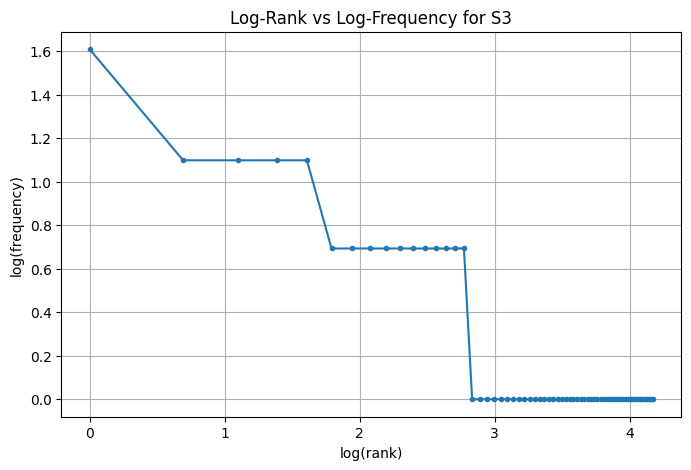


TOP 5 BIGRAMS OF S1
[(('.', 'the'), 5), (('.', 'i'), 5), (('.', 'it'), 3), (('yesterday', '.'), 3), (('.', 'is'), 3)]

TOP 5 BIGRAMS OF S3
[(('assignment', 'deadline'), 2), (('worked', 'yesterday'), 2), (('ca', "n't"), 2), (('another', 'solution'), 2), (('stopped', 'syncing'), 2)]


In [18]:
# Your code

import math
import matplotlib.pyplot as plt
from collections import Counter
from nltk.util import ngrams
from nltk.stem import PorterStemmer

porter = PorterStemmer()

# Build the four token sets from all generated tickets
S1 = []
S2 = []
S3 = []

for ticket in df["Ticket_Text"]:
    result = process_ticket(ticket)

    # S1: all tokens
    S1.extend(result["tokens"])

    # S2: tokens without punctuation
    S2.extend([t for t in result["tokens"] if not is_punct(t)])

    # S3: final tokens after removing punctuation and stopwords
    S3.extend(result["final"])

# S4: final tokens after Porter stemming
S4 = [porter.stem(t) for t in S3]

# Calculate corpus statistics
corpora = {
    "S1 - All tokens": S1,
    "S2 - No punctuation": S2,
    "S3 - Final tokens": S3,
    "S4 - Porter stemmed": S4
}

print("CORPUS STATISTICS")
print("-" * 55)

for name, tokens in corpora.items():
    total = len(tokens)
    unique = len(set(tokens))
    ttr = unique / total if total else 0

    print(f"\n{name}")
    print("Total tokens:", total)
    print("Unique tokens:", unique)
    print(f"TTR: {ttr:.4f}")

# Top 10 words of S1 and S3
print("\nTOP 10 WORDS OF S1")
print(Counter(S1).most_common(10))

print("\nTOP 10 WORDS OF S3")
print(Counter(S3).most_common(10))

# Log(rank) vs log(frequency) for S3
frequencies = Counter(S3).most_common()
ranks = list(range(1, len(frequencies) + 1))
freq_values = [frequency for word, frequency in frequencies]

plt.figure(figsize=(8, 5))
plt.plot(
    [math.log(rank) for rank in ranks],
    [math.log(freq) for freq in freq_values],
    marker="."
)
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("Log-Rank vs Log-Frequency for S3")
plt.grid(True)
plt.show()

# Top 5 bigrams
print("\nTOP 5 BIGRAMS OF S1")
print(Counter(ngrams(S1, 2)).most_common(5))

print("\nTOP 5 BIGRAMS OF S3")
print(Counter(ngrams(S3, 2)).most_common(5))


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*The Type-Token Ratio (TTR) changes from S1 to S4 because preprocessing and stemming affect the number of total and unique tokens. S1 includes all tokens, including punctuation and stopwords. S3 removes punctuation and stopwords, while S4 applies Porter stemming to the final tokens. Stemming combines related word forms into common stems, which generally reduces the number of unique tokens. Therefore, TTR may decrease from S1 to S4, although the exact change depends on the generated dataset.